# Starting of project
Everything from here on down are cells that are working so far, every before this was either testing something or just not working

In [ ]:
%pip install tensorflow
%pip install keras

In [ ]:
%pip install Keras-Preprocessing

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.6/42.6 kB 1.2 MB/s eta 0:00:00


In [ ]:
!pip install transformers
from transformers import AutoTokenizer

In [ ]:
import matplotlib.pyplot as plt
from nltk.corpus import wordnet
import random
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, Dropout, Embedding, LSTM, concatenate, Activation, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import nltk
nltk.download('punkt')
from nltk.tokenize import word_tokenize
import os
from PIL import Image

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


In [ ]:
!pip install kaggle --upgrade
import os
os.environ['KAGGLE_USERNAME'] = "XXXXXX"
os.environ['KAGGLE_KEY'] = "XXXXXXXXXXXXXXXXXXXXXX" # Enter your Kaggle key here

# For Flickr 8k
!kaggle datasets download -d adityajn105/flickr8k
!unzip flickr8k.zip
dataset = "8k"


Streaming output truncated to the last 5000 lines.
  inflating: Images/2844846111_8c1cbfc75d.jpg  
  inflating: Images/2844963839_ff09cdb81f.jpg  
  inflating: Images/2845246160_d0d1bbd6f0.jpg  
  inflating: Images/2845691057_d4ab89d889.jpg  
  inflating: Images/2845845721_d0bc113ff7.jpg  
  inflating: Images/2846037553_1a1de50709.jpg  
  inflating: Images/2846785268_904c5fcf9f.jpg  
  inflating: Images/2846843520_b0e6211478.jpg  
  inflating: Images/2847514745_9a35493023.jpg  
  inflating: Images/2847615962_c330bded6e.jpg  
  inflating: Images/2847859796_4d9cb0d31f.jpg  
  inflating: Images/2848266893_9693c66275.jpg  
  inflating: Images/2848571082_26454cb981.jpg  
  inflating: Images/2848895544_6d06210e9d.jpg  
  inflating: Images/2848977044_446a31d86e.jpg  
  inflating: Images/2849194983_2968c72832.jpg  
  inflating: Images/2850719435_221f15e951.jpg  
  inflating: Images/2851198725_37b6027625.jpg  
  inflating: Images/2851304910_b5721199bc.jpg  
  inflating: Images/2851931813_eaf8ed

In [ ]:
captions = open('/content/captions.txt', 'r').read()

# Create a dictionary mapping image names to captions

def load_captions(captions):
    mapping = {}
    for line in captions.strip().split('\n'):
        tokens = line.strip().split(',')
        if len(tokens) < 2:
            continue
        image_id, caption = tokens[0], tokens[1]
        image_id = image_id.split('#')[0]
        if image_id not in mapping:
            mapping[image_id] = []
        mapping[image_id].append(caption)
    return mapping

all_captions_mapping = load_captions(captions)
print(f"Total images: {len(all_captions_mapping)}")

Total images: 8092


In [ ]:
# Selecting the first 100 images

all_captions_mapping.pop('image', None)
captions_mapping = {k: all_captions_mapping[k] for k in list(all_captions_mapping.keys())[:100]}

In [ ]:
from tensorflow.keras.applications.vgg16 import preprocess_input

def preprocess_image(image_path):

    img = Image.open(image_path)
    img = img.resize((224, 224))
    img = np.array(img)

    if img.shape[-1] == 4:
        img = img[..., :3]

    img = preprocess_input(img)
    return img

In [ ]:
from tensorflow.keras.applications.vgg16 import preprocess_input
import numpy as np

def preprocess_image(image_path):
    img = Image.open(image_path).resize((224, 224))
    img = np.array(img)
    if img.shape[-1] == 4:  # Handle images with alpha channel
        img = img[..., :3]
    img = preprocess_input(img)
    return img

def extract_features(cnn_model, image_dir, captions_mapping):
    features = {}
    for img_id in captions_mapping.keys():
        img_path = os.path.join(image_dir, img_id)
        img = preprocess_image(img_path)
        img = np.expand_dims(img, axis=0)  # Add batch dimension
        features[img_id] = cnn_model.predict(img, verbose=0).flatten()
    return features


In [ ]:
from tensorflow.keras.layers import BatchNormalization
def build_cnn_model():
    inputs = Input(shape=(224, 224, 3))

    x = Conv2D(16, (3, 3), activation='relu', padding='same')(inputs)
    x = MaxPooling2D((2, 2))(x)

    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = MaxPooling2D((2, 2))(x)

    x = Flatten()(x)
    x = Dense(256, activation='relu')(x)
    outputs = x

    model = Model(inputs, outputs, name='CNN_Model')
    return model

cnn_model = build_cnn_model()
cnn_model.summary()
cnn_model.compile(optimizer='adam', loss='categorical_crossentropy')


Model: "CNN_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 224, 224, 16)        │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 32)        │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 100352)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │      25,690,368 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 25,695,456 (98.02 MB)

 Trainable params: 25,695,456 (98.02 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 20

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_fixed_captions(captions_mapping, tokenizer, max_length):
    tokenized_mapping = {}
    for img_id, captions in captions_mapping.items():
        tokenized_mapping[img_id] = [
            tokenizer.encode(caption, padding='max_length', truncation=True, max_length=max_length)
            for caption in captions
        ]
    return tokenized_mapping

tokenized_captions = tokenize_fixed_captions(captions_mapping, tokenizer, MAX_LENGTH)
VOCAB_SIZE = tokenizer.vocab_size


/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
def create_sequences_fixed(tokenized_mapping, features, max_length):
    X1, X2, y = [], [], []
    for img_id, sequences in tokenized_mapping.items():
        feature = features[img_id]
        for seq in sequences:
            for i in range(1, len(seq)):
                input_seq, output_word = seq[:i], seq[i]
                input_seq = pad_sequences([input_seq], maxlen=max_length, padding='post')[0]
                output_word = tf.keras.utils.to_categorical([output_word], num_classes=VOCAB_SIZE)[0]
                X1.append(feature)
                X2.append(input_seq)
                y.append(output_word)
    return np.array(X1), np.array(X2), np.array(y)


In [ ]:
def lstm_model(vocab_size, max_length):
    inputs1 = Input(shape=(256,))
    fe1 = Dropout(0.5)(inputs1)
    fe2 = Dense(256, activation='relu')(fe1)

    inputs2 = Input(shape=(max_length,))
    se1 = Embedding(vocab_size, 256, mask_zero=True)(inputs2)
    se2 = Dropout(0.5)(se1)
    se3 = LSTM(256)(se2)

    decoder1 = concatenate([fe2, se3])
    decoder2 = Dense(256, activation='relu')(decoder1)
    outputs = Dense(vocab_size, activation='softmax')(decoder2)

    model = Model(inputs=[inputs1, inputs2], outputs=outputs)
    return model

lstm_model = lstm_model(VOCAB_SIZE, MAX_LENGTH)
lstm_model.compile(loss='categorical_crossentropy', optimizer='adam')
lstm_model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2             │ (None, 20)             │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ input_layer_1             │ (None, 256)            │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ embedding (Embedding)     │ (None, 20, 256)        │      7,813,632 │ input_layer_2[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout (Dropout)         │ (None, 256)            │              0 │ input_layer_1[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_1 (Dropout)       │ (None, 20, 256)        │              0 │ embedding[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ not_equal (NotEqual)      │ (None, 20)             │              0 │ input_layer_2[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_1 (Dense)           │ (None, 256)            │         65,792 │ dropout[0][0]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ lstm (LSTM)               │ (None, 256)            │        525,312 │ dropout_1[0][0],       │
│                           │                        │                │ not_equal[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ concatenate (Concatenate) │ (None, 512)            │              0 │ dense_1[0][0],         │
│                           │                        │                │ lstm[0][0]             │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_2 (Dense)           │ (None, 256)            │        131,328 │ concatenate[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_3 (Dense)           │ (None, 30522)          │      7,844,154 │ dense_2[0][0]          │
└───────────────────────────┴────────────────────────┴────────────────┴────────────────────────┘

 Total params: 16,380,218 (62.49 MB)

 Trainable params: 16,380,218 (62.49 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from sklearn.model_selection import train_test_split
image_dir = '/content/Images'
features = extract_features(cnn_model, image_dir, captions_mapping)
X1, X2, y = create_sequences_fixed(tokenized_captions, features, MAX_LENGTH)

X1_train, X1_val, X2_train, X2_val, y_train, y_val = train_test_split(X1, X2, y, test_size=0.2, random_state=42)

history = lstm_model.fit(
    [X1_train, X2_train], y_train,
    epochs=20, batch_size=64,
    validation_data=([X1_val, X2_val], y_val)
)


Epoch 1/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 56s 444ms/step - loss: 5.6142 - val_loss: 4.0300
Epoch 2/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 80s 432ms/step - loss: 3.5383 - val_loss: 3.6018
Epoch 3/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 83s 438ms/step - loss: 3.2260 - val_loss: 3.5168
Epoch 4/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 81s 428ms/step - loss: 3.1261 - val_loss: 3.4017
Epoch 5/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 87s 473ms/step - loss: 2.9547 - val_loss: 3.3381
Epoch 6/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 57s 476ms/step - loss: 2.8443 - val_loss: 3.3007
Epoch 7/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 58s 488ms/step - loss: 2.7864 - val_loss: 3.2260
Epoch 8/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 77s 445ms/step - loss: 2.6399 - val_loss: 3.2469
Epoch 9/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 53s 442ms/step - loss: 2.5509 - val_loss: 3.2212
Epoch 10/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 84s 455ms/step - loss: 2.4161 - val_loss: 3.1992
Epoch 11/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 79s 435ms/step - loss: 2.2618 - val_loss: 3.2206
Epoch 12/20
119/119

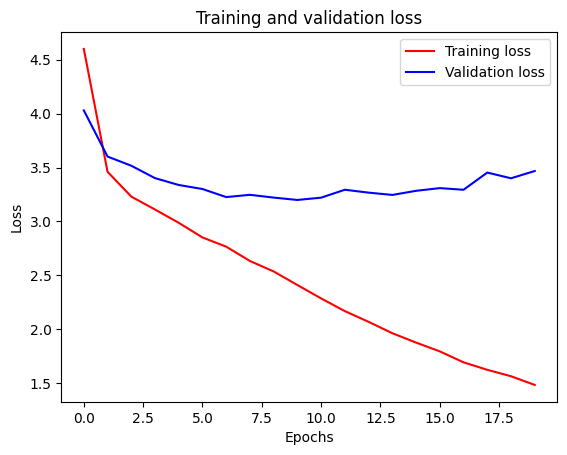

In [ ]:
epochs = [i for i in range(20)]
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.plot(epochs, loss, 'r', label='Training loss')
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

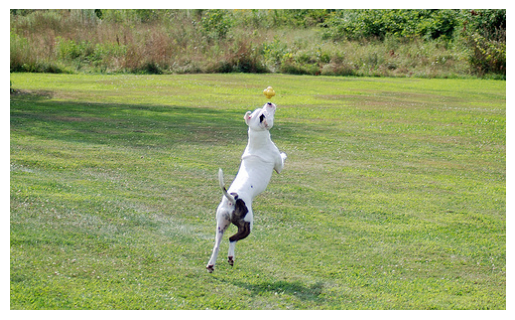

Generated caption: trying a dog jumps to catch a ballair.


In [ ]:
import matplotlib.pyplot as plt
def generate_caption(model, tokenizer, photo, max_length):
    input_seq = []
    for _ in range(max_length):
        sequence = pad_sequences([input_seq], maxlen=max_length, padding='post')
        yhat = model.predict([photo, sequence], verbose=0)
        yhat = np.argmax(yhat)
        if yhat == tokenizer.pad_token_id:
            break
        input_seq.append(yhat)
    return tokenizer.decode(input_seq, skip_special_tokens=True)

example_feature = features[list(captions_mapping.keys())[15]]
example_feature = np.expand_dims(example_feature, axis=0)
caption = generate_caption(lstm_model, tokenizer, example_feature, MAX_LENGTH)
img = Image.open('/content/Images/' + list(captions_mapping.keys())[15])
plt.imshow(img)
plt.axis('off')
plt.show()
print(f"Generated caption: {caption}")



In [ ]:
!pip install rouge-score

  Preparing metadata (setup.py) ... done
  Created wheel for rouge-score: filename=rouge_score-0.1.2-py3-none-any.whl size=24935 sha256=617376f077fefd6799cf68f20b303114cba8729abd5d702ee7a87ad1c4f62ec8
  Stored in directory: /root/.cache/pip/wheels/5f/dd/89/461065a73be61a532ff8599a28e9beef17985c9e9c31e541b4
Successfully built rouge-score


In [ ]:
from nltk.translate.bleu_score import corpus_bleu
import nltk
nltk.download('wordnet')
from nltk.translate.meteor_score import meteor_score
from rouge_score import rouge_scorer
def evaluate_model(model, captions_mapping, features, tokenizer, max_length):
    actual, predicted = [], []
    for img_id, captions_list in captions_mapping.items():
        photo = features[img_id].reshape(1, -1)
        y_pred = generate_caption(model, tokenizer, photo, max_length)
        actual.append([caption.split() for caption in captions_list])
        predicted.append(y_pred.split())
        bleu1 = corpus_bleu(actual, predicted, weights=(1.0, 0, 0, 0))
    print(f'BLEU-1: {bleu1:.4f}')

    meteor_scores = []
    rouge_1_precision = []
    rouge_2_precision = []
    rouge_l_precision = []
    rouge_1_recall = []
    rouge_2_recall = []
    rouge_l_recall = []
    rouge_1_fmeasure = []
    rouge_2_fmeasure = []
    rouge_l_fmeasure = []
    scorer = rouge_scorer.RougeScorer(['rouge1','rouge2', 'rougeL'], use_stemmer=True)
    for ref, hyp in zip(actual, predicted):
        meteor_scores.append(meteor_score(ref, hyp))
        scores = scorer.score(' '.join(ref[0]), ' '.join(hyp) )
        rouge_1_precision.append(scores['rouge1'].precision)
        rouge_2_precision.append(scores['rouge2'].precision)
        rouge_l_precision.append(scores['rougeL'].precision)
        rouge_1_recall.append(scores['rouge1'].recall)
        rouge_2_recall.append(scores['rouge2'].recall)
        rouge_l_recall.append(scores['rougeL'].recall)
        rouge_1_fmeasure.append(scores['rouge1'].fmeasure)
        rouge_2_fmeasure.append(scores['rouge2'].fmeasure)
        rouge_l_fmeasure.append(scores['rougeL'].fmeasure)

    avg_meteor = sum(meteor_scores) / len(meteor_scores) if meteor_scores else 0
    print(f'METEOR: {avg_meteor:.4f}')
    print(f'ROUGE-1 Precision: {sum(rouge_1_precision) / len(rouge_1_precision):.4f}')
    print(f'ROUGE-1 Recall: {sum(rouge_1_recall) / len(rouge_1_recall):.4f}')
    print(f'ROUGE-1 F-Measure: {sum(rouge_1_fmeasure) / len(rouge_1_fmeasure):.4f}')

    print(f'ROUGE-2 Precision: {sum(rouge_2_precision) / len(rouge_2_precision):.4f}')
    print(f'ROUGE-2 Recall: {sum(rouge_2_recall) / len(rouge_2_recall):.4f}')
    print(f'ROUGE-2 F-Measure: {sum(rouge_2_fmeasure) / len(rouge_2_fmeasure):.4f}')

    print(f'ROUGE-L Precision: {sum(rouge_l_precision) / len(rouge_l_precision):.4f}')
    print(f'ROUGE-L Recall: {sum(rouge_l_recall) / len(rouge_l_recall):.4f}')
    print(f'ROUGE-L F-Measure: {sum(rouge_l_fmeasure) / len(rouge_l_fmeasure):.4f}')

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [ ]:
evaluate_model(lstm_model, captions_mapping, features, tokenizer, MAX_LENGTH)

BLEU-1: 0.3852
METEOR: 0.2213
ROUGE-1 Precision: 0.5111
ROUGE-1 Recall: 0.2610
ROUGE-1 F-Measure: 0.3095
ROUGE-2 Precision: 0.1612
ROUGE-2 Recall: 0.0992
ROUGE-2 F-Measure: 0.1119
ROUGE-L Precision: 0.4751
ROUGE-L Recall: 0.2395
ROUGE-L F-Measure: 0.2846


METEOR and CIDEr scores need to implement later